<center><h1>zheng_yiyi_HW5</h1></center>
<br>
<br>

Name: yiyi zheng
<br>
Github Username: yiyizheng111
<br>
USC ID: 7092417109

## 1. Decision Trees as Interpretable Models

Import packages

In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

### (a) Obtain Data

Get the Accute Inamations Data Set

In [3]:
# Path to data folder
DATA_DIR = Path("Homework 5 Data")

# Check folder
print("Data folder exists:", DATA_DIR.exists())

# Show inside
print("\nFiles in the data folder:")

for file_path in sorted(DATA_DIR.rglob("*")):
    if file_path.is_file() and not file_path.name.startswith("."):
        print(file_path.relative_to(DATA_DIR))

Data folder exists: True

Files in the data folder:
Simplifying Decision Tree Interpretability with Python & Scikit-learn - KDnuggets.pdf
communities.data
communities.names
diagnosis.data
diagnosis.names


In [4]:
# Read the Acute Inflammations dataset

column_names = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning_urethra",
    "bladder_inflammation",
    "nephritis"
]

acute_df = pd.read_csv(
    DATA_DIR / "diagnosis.data",
    sep=r"\s+",
    header=None,
    names=column_names,
    encoding="utf-16",
    engine="python"
)

# Convert temperature
acute_df["temperature"] = (
    acute_df["temperature"]
    .astype(str)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

# Check dataset
print("Dataset shape:", acute_df.shape)

print("\nData types:")
print(acute_df.dtypes)

print("\nMissing values:")
print(acute_df.isnull().sum())

# Show first 5 rows
acute_df.head()

Dataset shape: (120, 8)

Data types:
temperature             float64
nausea                   object
lumbar_pain              object
urine_pushing            object
micturition_pains        object
burning_urethra          object
bladder_inflammation     object
nephritis                object
dtype: object

Missing values:
temperature             0
nausea                  0
lumbar_pain             0
urine_pushing           0
micturition_pains       0
burning_urethra         0
bladder_inflammation    0
nephritis               0
dtype: int64


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

/var/folders/2x/v2pz4lrx7fj9q1_9pxw6939h0000gn/T/ipykernel_72006/895715169.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  acute_numeric = acute_df.replace({


Number of observations: 120
Number of features: 6
Number of targets: 2

Tree depth: 4
Number of leaves: 6
Training accuracy: 1.0


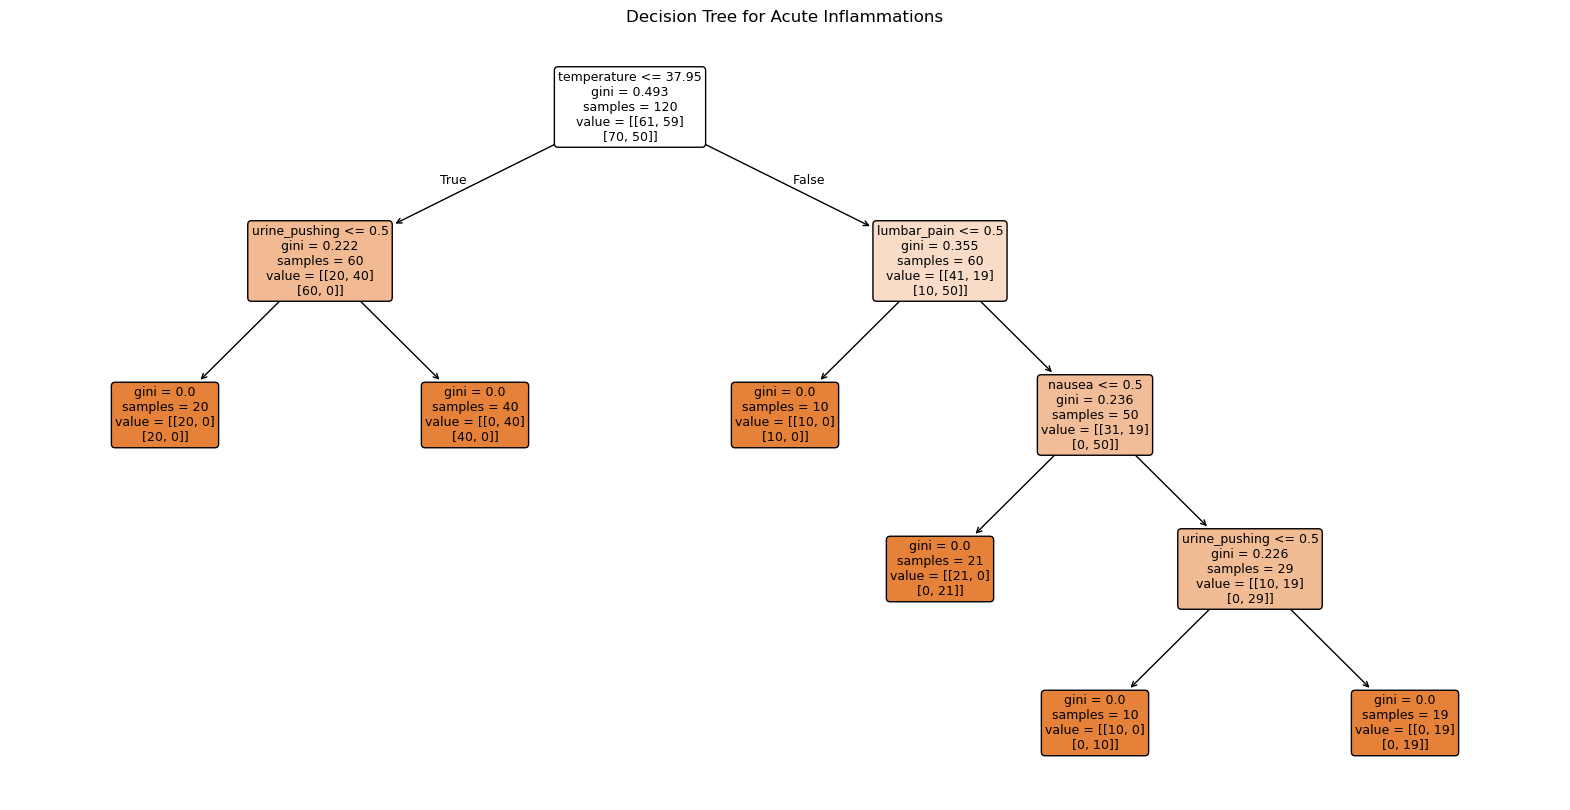

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Convert yes/no to 1/0
acute_numeric = acute_df.replace({
    "yes": 1,
    "no": 0
})

# Select features and target variables
feature_cols = column_names[:6]
target_cols = column_names[6:]

X = acute_numeric[feature_cols]
y = acute_numeric[target_cols]

# Build a decision tree using whole dataset
tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X, y)

# Check the tree
print("Number of observations:", len(X))
print("Number of features:", X.shape[1])
print("Number of targets:", y.shape[1])

print("\nTree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())
print("Training accuracy:", tree_model.score(X, y))

# Plot decision tree
plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=feature_cols,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree for Acute Inflammations")
plt.show()

Using all 120 observations to built a decision tree for predict the two diseases.

The tree has a depth of 4 and 6 leaf nodes. The first split is based on temperature, followed by urine_pushing, lumbar_pain, and nausea.

The training accuracy was 100%. All observations were classified correctly in the training data.

However, this does not mean the model will always have the same accuracy on new data.

### (c) Convert the decision rules

In [6]:
# Convert the decision tree into IF-THEN rules

tree = tree_model.tree_

rules = []

def get_rules(node, conditions):

    # Check if this node is a leaf
    if tree.children_left[node] == -1:

        predictions = []

        for i, target in enumerate(target_cols):
            class_index = np.argmax(tree.value[node][i])
            prediction = tree_model.classes_[i][class_index]

            label = "yes" if prediction == 1 else "no"
            predictions.append(f"{target} = {label}")

        rules.append((conditions, predictions))

    else:
        feature = feature_cols[tree.feature[node]]
        threshold = tree.threshold[node]

        # Conditions for temperature
        if feature == "temperature":
            left_condition = f"{feature} <= {threshold:.2f}"
            right_condition = f"{feature} > {threshold:.2f}"

        # Conditions for yes/no features
        else:
            left_condition = f"{feature} = no"
            right_condition = f"{feature} = yes"

        # Left branch
        get_rules(
            tree.children_left[node],
            conditions + [left_condition]
        )

        # Right branch
        get_rules(
            tree.children_right[node],
            conditions + [right_condition]
        )


# Start from the root node
get_rules(0, [])

# Print all rules
for i, (conditions, predictions) in enumerate(rules, start=1):

    print(f"Rule {i}:")

    print("IF " + " AND ".join(conditions))

    print("THEN " + " AND ".join(predictions))

    print()

print("Total number of rules:", len(rules))

Rule 1:
IF temperature <= 37.95 AND urine_pushing = no
THEN bladder_inflammation = no AND nephritis = no

Rule 2:
IF temperature <= 37.95 AND urine_pushing = yes
THEN bladder_inflammation = yes AND nephritis = no

Rule 3:
IF temperature > 37.95 AND lumbar_pain = no
THEN bladder_inflammation = no AND nephritis = no

Rule 4:
IF temperature > 37.95 AND lumbar_pain = yes AND nausea = no
THEN bladder_inflammation = no AND nephritis = yes

Rule 5:
IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = no
THEN bladder_inflammation = no AND nephritis = yes

Rule 6:
IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = yes
THEN bladder_inflammation = yes AND nephritis = yes

Total number of rules: 6


I converted the decision tree into 6 IF-THEN rules.

These rules use temperature, urine_pushing, lumbar_pain, and nausea to predict the two diseases.

Each rule has some conditions and gives the prediction for bladder_inflammation and nephritis.

The rules are easy to understand because we can follow the conditions from the top of the tree to each leaf node.

### (d) Cost-Complexity Pruning

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Get possible ccp_alpha values
path = tree_model.cost_complexity_pruning_path(X, y)
ccp_alphas = np.unique(path.ccp_alphas)

# Combine the two target labels for stratified CV
y_combined = y.astype(str).agg("_".join, axis=1)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(cv.split(X, y_combined))

pruning_results = []

for alpha in ccp_alphas:

    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    # 5-fold cross-validation
    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv_splits,
        scoring="accuracy"
    )

    # Check tree size
    model.fit(X, y)

    pruning_results.append({
        "ccp_alpha": alpha,
        "CV Accuracy": scores.mean(),
        "Tree Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
        "Training Accuracy": model.score(X, y)
    })

pruning_df = pd.DataFrame(pruning_results)

print("Cost-Complexity Pruning Results:")
print(pruning_df.round(4).to_string(index=False))

Cost-Complexity Pruning Results:
 ccp_alpha  CV Accuracy  Tree Depth  Leaves  Training Accuracy
    0.0000       1.0000           4       6             1.0000
    0.0491       0.8667           2       4             0.8417
    0.0795       0.7667           2       3             0.7583
    0.1111       0.6333           1       2             0.5917
    0.2042       0.4500           0       1             0.2500


Selected ccp_alpha: 0.0491
Pruned tree depth: 2
Number of leaves: 4
Training accuracy: 0.8417


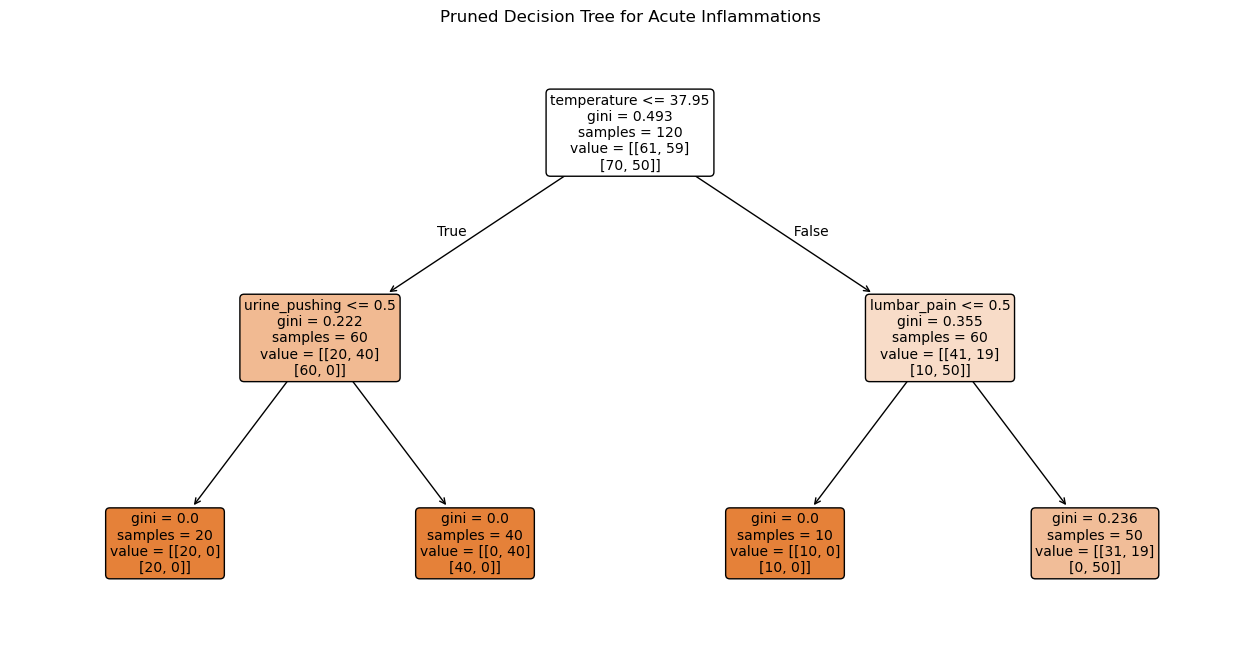

In [8]:
# Build a smaller decision tree using cost-complexity pruning

# Select the alpha that gives 4 leaf nodes
selected_alpha = pruning_df.loc[
    pruning_df["Leaves"] == 4, "ccp_alpha"
].iloc[0]

pruned_model = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=selected_alpha
)

pruned_model.fit(X, y)

# Check pruned tree
print("Selected ccp_alpha:", round(selected_alpha, 4))
print("Pruned tree depth:", pruned_model.get_depth())
print("Number of leaves:", pruned_model.get_n_leaves())
print("Training accuracy:", round(pruned_model.score(X, y), 4))

# Plot pruned decision tree
plt.figure(figsize=(16, 8))

plot_tree(
    pruned_model,
    feature_names=feature_cols,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Pruned Decision Tree for Acute Inflammations")
plt.show()

In [9]:
# Convert pruned decision tree into IF-THEN rules

pruned_tree = pruned_model.tree_
pruned_rules = []

def get_pruned_rules(node, conditions):

    if pruned_tree.feature[node] != -2:

        feature = feature_cols[pruned_tree.feature[node]]
        threshold = pruned_tree.threshold[node]

        # Left branch
        get_pruned_rules(
            pruned_tree.children_left[node],
            conditions + [f"{feature} <= {threshold:.2f}"]
        )

        # Right branch
        get_pruned_rules(
            pruned_tree.children_right[node],
            conditions + [f"{feature} > {threshold:.2f}"]
        )

    else:

        predictions = []

        for i, target in enumerate(target_cols):

            class_index = np.argmax(pruned_tree.value[node][i])
            prediction = pruned_model.classes_[i][class_index]

            label = "yes" if prediction == 1 else "no"

            predictions.append(f"{target} = {label}")

        rule = (
            "IF " + " AND ".join(conditions)
            + "\nTHEN " + " AND ".join(predictions)
        )

        pruned_rules.append(rule)


get_pruned_rules(0, [])

for i, rule in enumerate(pruned_rules, 1):
    print(f"Rule {i}:")
    print(rule)
    print()

print("Total number of rules:", len(pruned_rules))

Rule 1:
IF temperature <= 37.95 AND urine_pushing <= 0.50
THEN bladder_inflammation = no AND nephritis = no

Rule 2:
IF temperature <= 37.95 AND urine_pushing > 0.50
THEN bladder_inflammation = yes AND nephritis = no

Rule 3:
IF temperature > 37.95 AND lumbar_pain <= 0.50
THEN bladder_inflammation = no AND nephritis = no

Rule 4:
IF temperature > 37.95 AND lumbar_pain > 0.50
THEN bladder_inflammation = no AND nephritis = yes

Total number of rules: 4


I used cost-complexity pruning to make the decision tree simpler,and tested different ccp_alpha values using 5-fold cross-validation.

The original decision tree had a depth of 4 and 6 leaf nodes. Its training accuracy and CV accuracy were both 100%.

When ccp_alpha = 0.0491, the tree depth decreased to 2, and the number of leaf nodes decreased to 4. The training accuracy was 84.17%, and the CV accuracy was 86.67%.

I also converted the pruned tree into 4 IF-THEN rules. The new tree is easier to understand because it has fewer conditions.

However, the accuracy decreased after pruning. In this case, the original decision tree performed better. I think the pruned tree is simpler, but the original tree is a better choice if we care more about prediction accuracy.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [10]:
# Question 2(a): Load Communities and Crime dataset

import re

# Read the column names from communities.names
with open(DATA_DIR / "communities.names", encoding="latin-1") as f:
    content = f.read()

crime_columns = re.findall(
    r"^\s*@attribute\s+(\S+)",
    content,
    flags=re.IGNORECASE | re.MULTILINE
)

# Load dataset
crime_df = pd.read_csv(
    DATA_DIR / "communities.data",
    header=None,
    na_values="?"
)

# Assign column names
print("Number of column names:", len(crime_columns))
print("Number of data columns:", crime_df.shape[1])

if len(crime_columns) == crime_df.shape[1]:
    crime_df.columns = crime_columns
else:
    print("Column names do not match. Please check the dataset.")

# Split dataset
# First 1495 rows for training, remaining rows for testing

crime_train = crime_df.iloc[:1495].copy()
crime_test = crime_df.iloc[1495:].copy()

print("\nDataset shape:", crime_df.shape)
print("Training set shape:", crime_train.shape)
print("Testing set shape:", crime_test.shape)

print("\nFirst 5 rows:")
display(crime_df.head())

Number of column names: 128
Number of data columns: 128

Dataset shape: (1994, 128)
Training set shape: (1495, 128)
Testing set shape: (499, 128)

First 5 rows:


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [11]:
# Question 2(b): Handle missing values

from sklearn.impute import SimpleImputer

# Remove nonpredictive features
nonpredictive_cols = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

# Define target variable
target_col = "ViolentCrimesPerPop"

# Separate features and target
X_train_raw = crime_train.drop(
    columns=nonpredictive_cols + [target_col]
)

X_test_raw = crime_test.drop(
    columns=nonpredictive_cols + [target_col]
)

y_train = crime_train[target_col]
y_test = crime_test[target_col]

# Check missing values before imputation
print("Missing values before imputation:")
print("Training set:", X_train_raw.isna().sum().sum())
print("Testing set:", X_test_raw.isna().sum().sum())

# Use median imputation
imputer = SimpleImputer(strategy="median")

# Fit on training data only
X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

# Apply to testing data
X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

# Check results
print("\nAfter imputation:")
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nMissing values after imputation:")
print("Training set:", X_train.isna().sum().sum())
print("Testing set:", X_test.isna().sum().sum())

print("\nNumber of predictor features:", X_train.shape[1])

Missing values before imputation:
Training set: 27633
Testing set: 9218

After imputation:
Training set shape: (1495, 122)
Testing set shape: (499, 122)

Missing values after imputation:
Training set: 0
Testing set: 0

Number of predictor features: 122


The dataset contains missing values. I removed 5 nonpredictive features: state, county, community, communityname, and fold.

Before imputation, there were 27,633 missing values in the training features and 9,218 missing values in the testing features.

I used median imputation to fill the missing values. I calculated the median using the training data and then applied it to both training and testing sets.

After imputation, there were no missing values left. The final dataset has 122 predictor features.

### (c) Plot a correlation matrix

Correlation matrix shape: (122, 122)


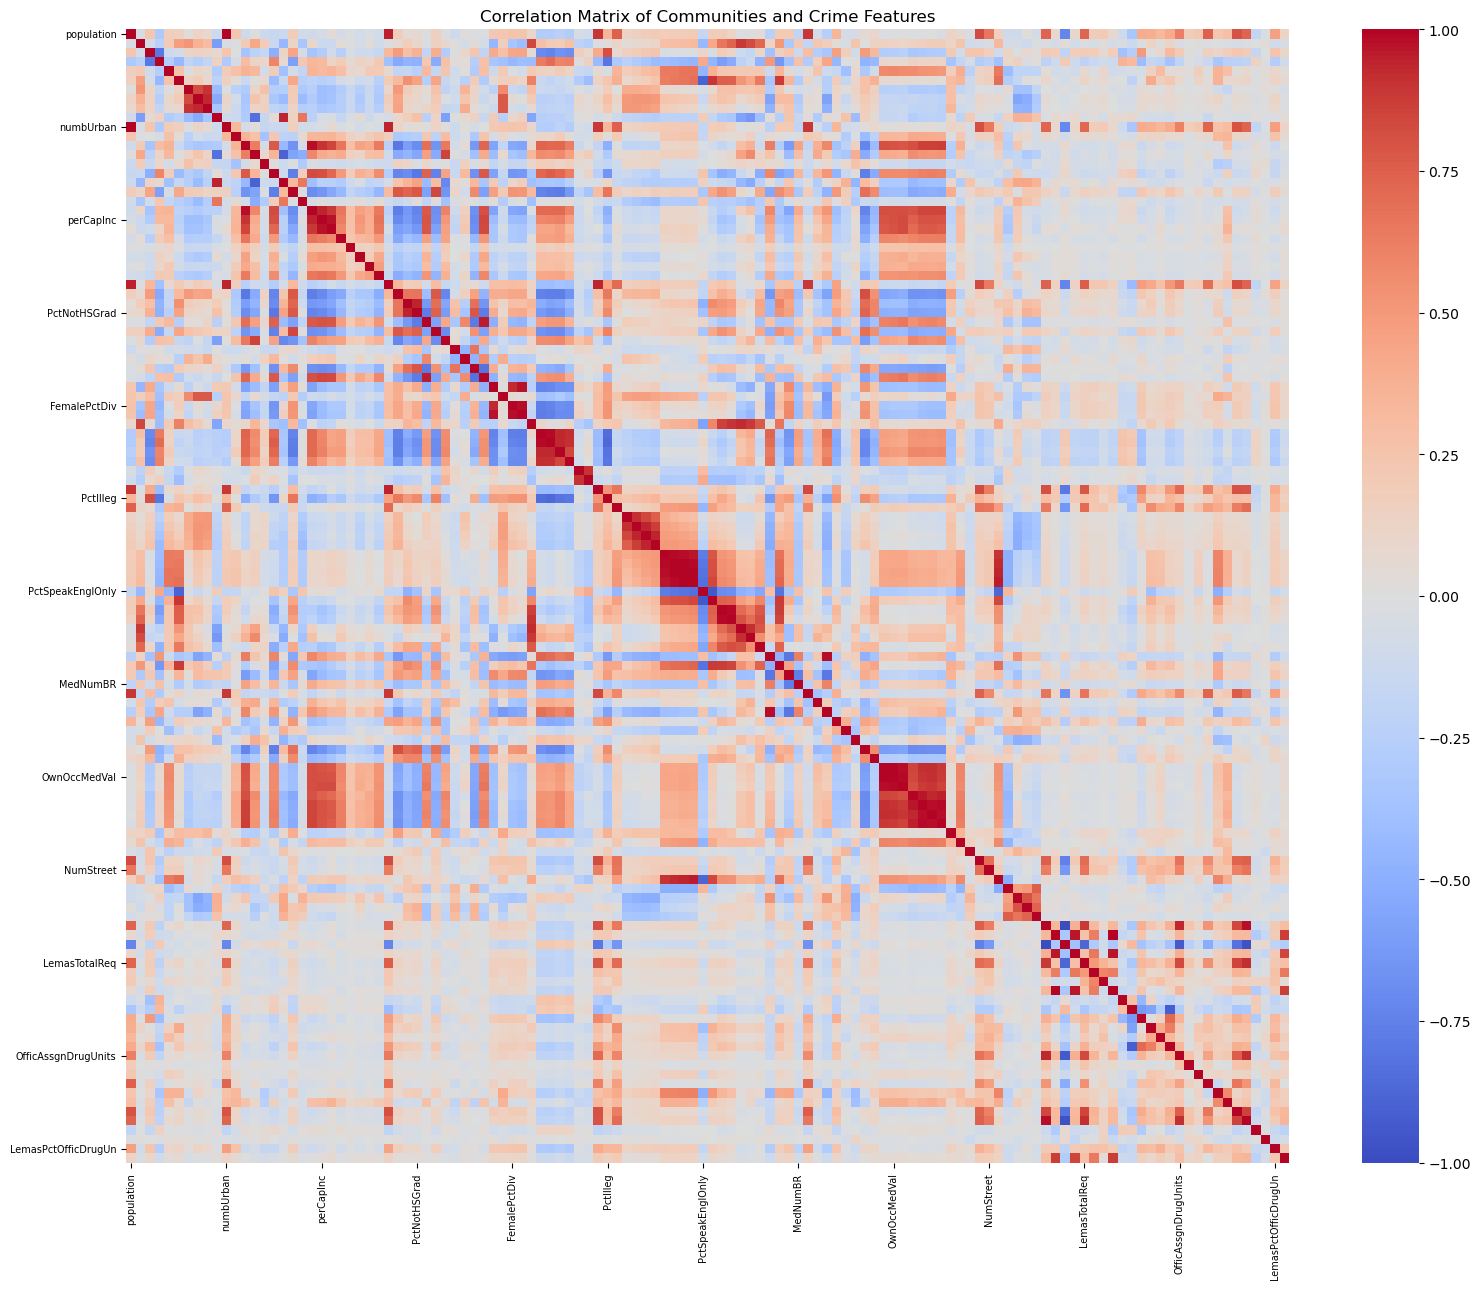

In [12]:
# Question 2(c): Plot the correlation matrix

import seaborn as sns

# Calculate correlation matrix
corr_matrix = X_train.corr()

print("Correlation matrix shape:", corr_matrix.shape)

# Plot correlation matrix
plt.figure(figsize=(16, 13))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=10,
    yticklabels=10
)

plt.title("Correlation Matrix of Communities and Crime Features")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

plt.show()

I plotted the correlation matrix for the 122 predictor features using the training data.

From the heatmap, we can see that some features have strong positive correlations, shown by the dark red areas. There are also some blue areas, which means negative correlations between features.

Many areas have lighter colors, so not all features are strongly correlated.

The correlation matrix shows that some features may contain similar information. This could be important when we build regression models later.

### (d) Calculate the Coefficient of Variation CV

In [13]:
# Question 2(d): Calculate Coefficient of Variation (CV)

# Calculate the mean 
feature_mean = X_train.mean()

# Calculate sample standard deviation
feature_std = X_train.std(ddof=1)

# Calculate CV = standard deviation / mean
# Replace zero means with NaN to avoid division by zero
feature_cv = feature_std / feature_mean.replace(0, np.nan)

# Create a table
cv_df = pd.DataFrame({
    "Mean": feature_mean,
    "Standard Deviation": feature_std,
    "CV": feature_cv
})

# Sort features by CV from highest to lowest
cv_df = cv_df.sort_values(
    by="CV",
    ascending=False
)

print("Number of features:", len(cv_df))
print("Features with undefined CV:", cv_df["CV"].isna().sum())

print("\nTop 15 features with highest CV:")
display(cv_df.head(15).round(4))

Number of features: 122
Features with undefined CV: 0

Top 15 features with highest CV:


,Mean,Standard Deviation,CV
PctPolicAsian,0.0163,0.0898,5.5271
NumStreet,0.0230,0.0987,4.2929
NumInShelters,0.0296,0.1027,3.4710
NumIlleg,0.0372,0.1138,3.0590
NumImmig,0.0306,0.0895,2.9266
LemasPctOfficDrugUn,0.0933,0.2382,2.5529
NumUnderPov,0.0568,0.1332,2.3424
LemasSwornFT,0.0287,0.0646,2.2480
population,0.0582,0.1304,2.2411
numbUrban,0.0646,0.1318,2.0385


I calculated the coefficient of variation (CV) for all 122 predictor features. I used the sample standard deviation divided by the mean of each feature.

All 122 features have valid CV values.

PctPolicAsian has the highest CV of 5.5271, followed by NumStreet with 4.2929 and NumInShelters with 3.4710.

A higher CV means the feature has more variation compared to its mean. However, it does not always mean the feature is more important for predicting crime rates.

### (e) Scatter plots and box plots for highest CV features

In [14]:
# Question 2(e): Select features with highest CV

# Select top 11 features
n_features = int(np.floor(np.sqrt(128)))

selected_features = cv_df.head(n_features).index.tolist()

print("Number of selected features:", n_features)

print("\nSelected features:")
for i, feature in enumerate(selected_features, 1):
    print(i, feature)

Number of selected features: 11

Selected features:
1 PctPolicAsian
2 NumStreet
3 NumInShelters
4 NumIlleg
5 NumImmig
6 LemasPctOfficDrugUn
7 NumUnderPov
8 LemasSwornFT
9 population
10 numbUrban
11 HousVacant


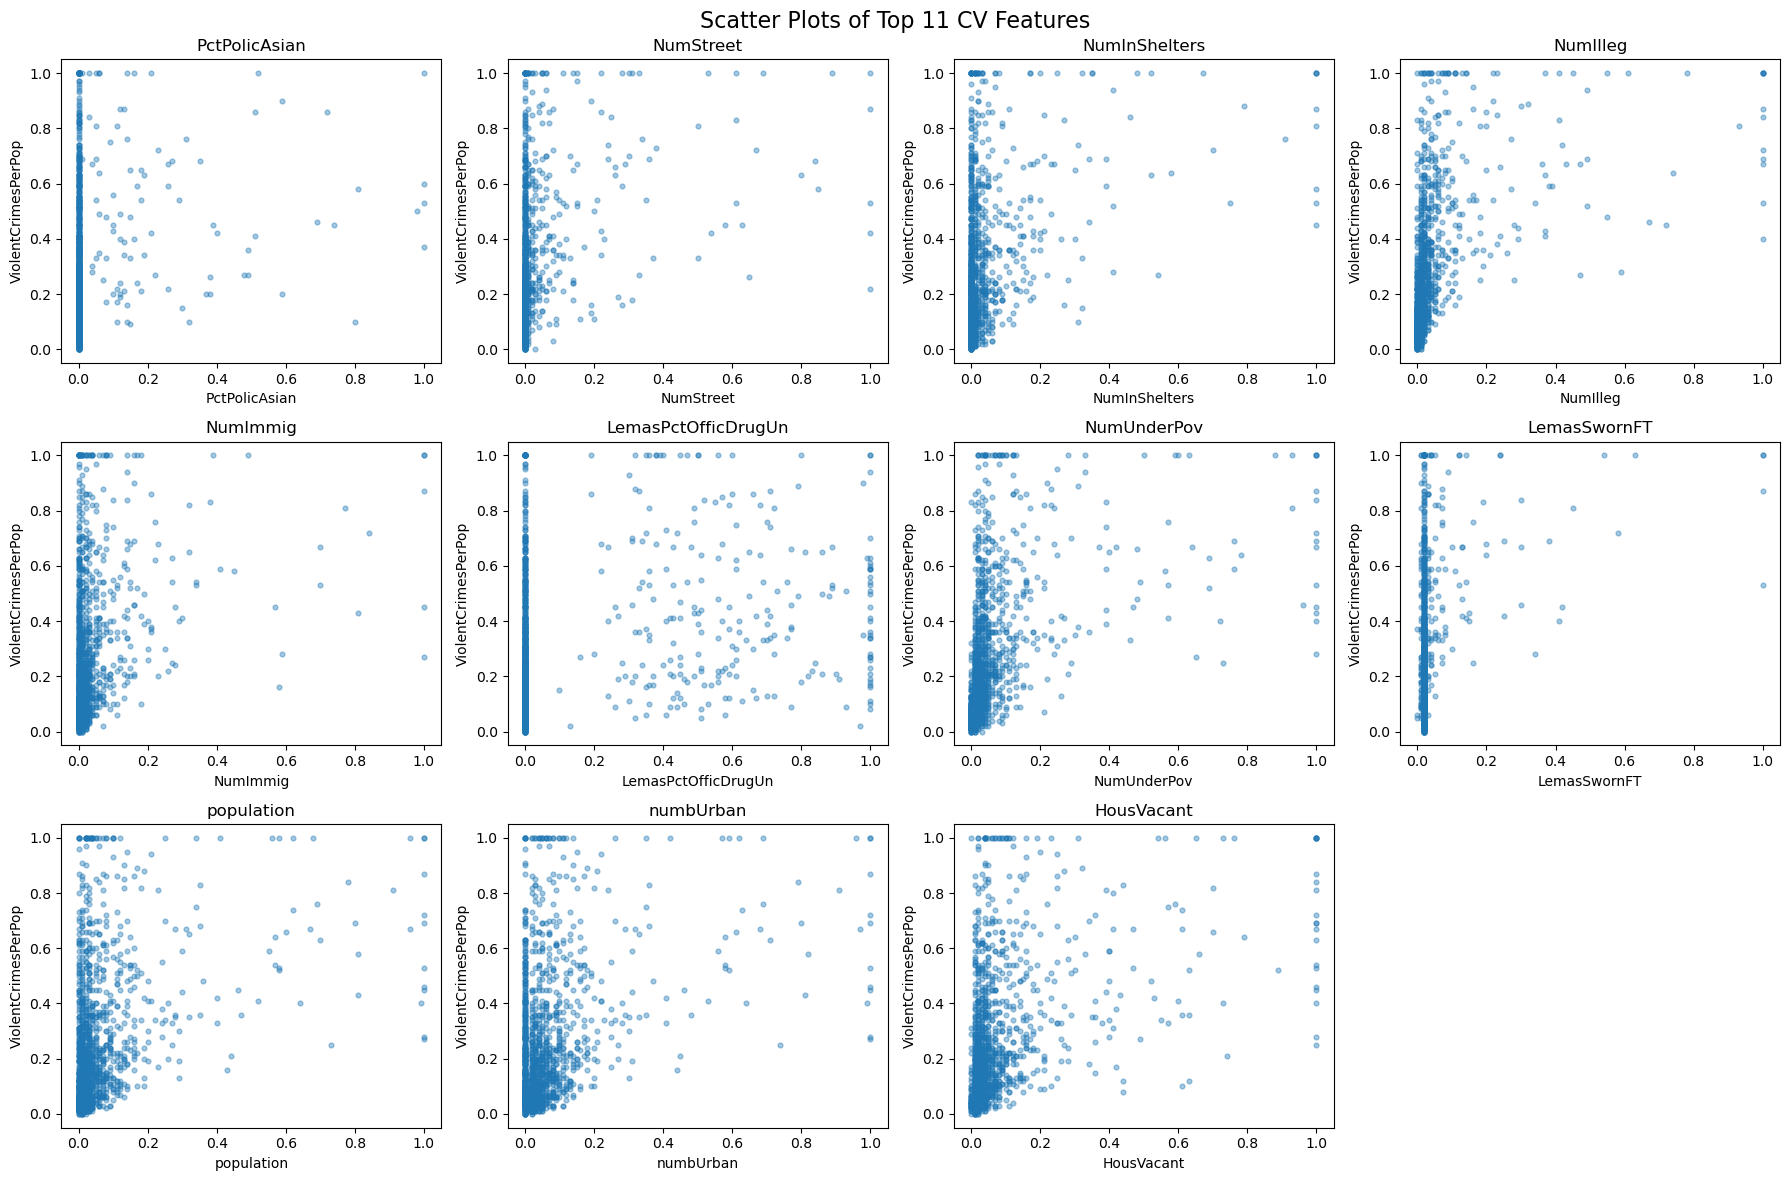

In [15]:
# Scatter plots for the selected features

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, feature in zip(axes.flat, selected_features):

    ax.scatter(
        X_train[feature],
        y_train,
        alpha=0.4,
        s=12
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("ViolentCrimesPerPop")

# Hide the extra subplot
for ax in axes.flat[len(selected_features):]:
    ax.axis("off")

plt.suptitle("Scatter Plots of Top 11 CV Features", fontsize=16)
plt.tight_layout()
plt.show()

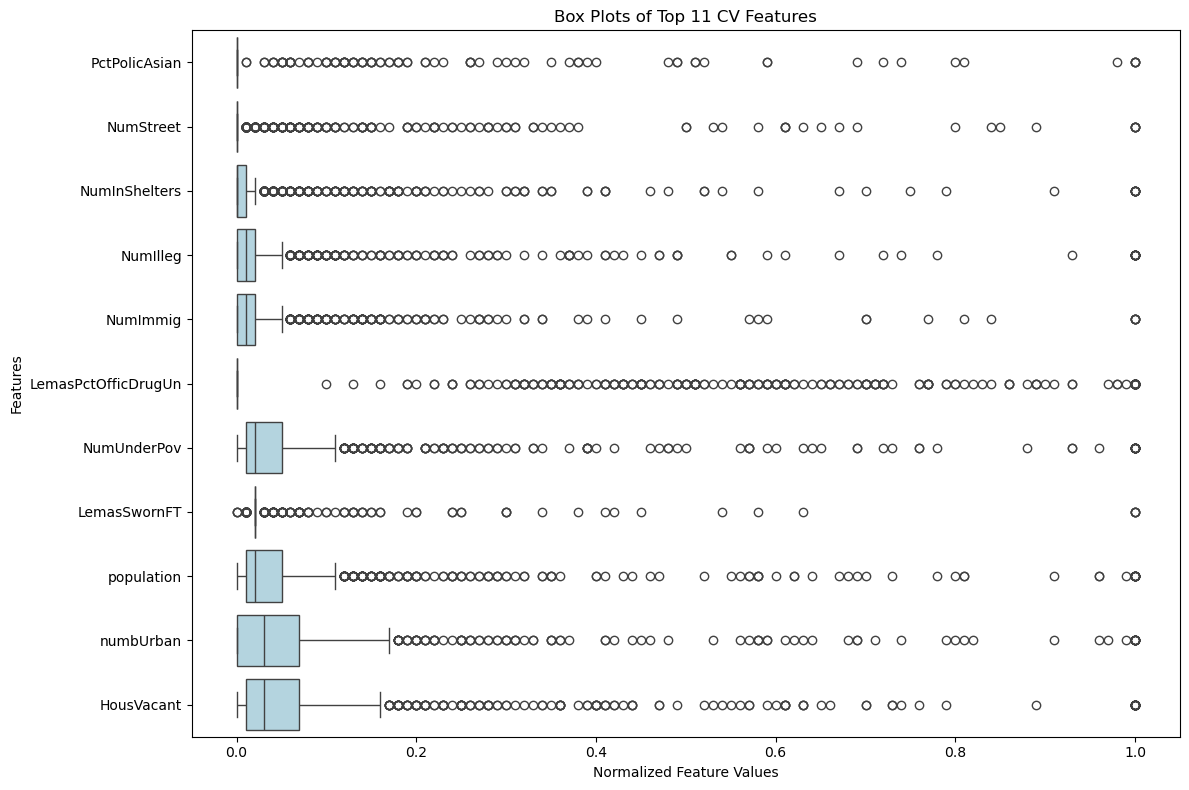

In [16]:
# Box plots for the selected features

plt.figure(figsize=(12, 8))

sns.boxplot(
    data=X_train[selected_features],
    orient="h",
    color="lightblue"
)

plt.title("Box Plots of Top 11 CV Features")
plt.xlabel("Normalized Feature Values")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

I selected the 11 features with the highest CV values and made scatter plots and box plots for them.

I can see that many features have values concentrated near zero in box plots.

From the scatter plots, most data points are concentrated at small feature values. However, the crime rates still vary a lot. I cannot see a very clear linear relationship for most of these features.

I think we cannot determine whether these features are statistically significant from scatter plots. The plots can help us understand the data, but we may need more analysis to check their significance.

Also, a high CV does not always mean a feature is important for predicting crime rates.

### (f) Fit a linear model

In [33]:
# Final Least Squares Regression

# Remove one duplicated feature
X_train_reg = X_train.drop(columns=["LemasSwFTPerPop"])
X_test_reg = X_test.drop(columns=["LemasSwFTPerPop"])

# Train the final model
ls_final = LinearRegression()
ls_final.fit(X_train_reg, y_train)

# Make predictions
y_pred_ls_final = ls_final.predict(X_test_reg)

# Calculate errors
ls_train_mse = mean_squared_error(
    y_train,
    ls_final.predict(X_train_reg)
)

ls_test_mse = mean_squared_error(
    y_test,
    y_pred_ls_final
)

print("Final Least Squares Regression:")
print("Number of features:", X_train_reg.shape[1])
print("Training MSE:", round(ls_train_mse, 6))
print("Testing MSE:", round(ls_test_mse, 6))

Final Least Squares Regression:
Number of features: 121
Training MSE: 0.016292
Testing MSE: 0.017966


I fitted a Least Squares Regression model using the training data.

At first, the test error was very large. I found that PolicPerPop and LemasSwFTPerPop had the same values in the training set. This made the regression coefficients unstable.

I removed LemasSwFTPerPop and fitted the model again using 121 features.

The final training MSE was 0.016292, and the test MSE was 0.017966. The new result was much more reasonable.

### (g) Fit a ridge regression model

In [21]:
# Question 2(g): Ridge Regression with Cross-Validation

from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

# Define lambda values
ridge_alphas = np.logspace(-4, 3, 50)

# Use 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Build Ridge Regression model
ridge_model = RidgeCV(
    alphas=ridge_alphas,
    cv=cv,
    scoring="neg_mean_squared_error"
)

# Train the model
ridge_model.fit(X_train_reg, y_train)

# Predict on the testing set
y_pred_ridge = ridge_model.predict(X_test_reg)

# Calculate test error
ridge_test_mse = mean_squared_error(
    y_test,
    y_pred_ridge
)

print("Ridge Regression Results:")
print("Best lambda (alpha):", ridge_model.alpha_)
print("Best CV MSE:", -ridge_model.best_score_)
print("Test MSE:", ridge_test_mse)

print("\nLeast Squares Test MSE:", ls_test_mse)
print("Ridge Test MSE:", ridge_test_mse)

Ridge Regression Results:
Best lambda (alpha): 3.727593720314938
Best CV MSE: 0.01942128525393421
Test MSE: 0.017454700417139837

Least Squares Test MSE: 0.017966352300160023
Ridge Test MSE: 0.017454700417139837


I fitted a Ridge Regression model using 5-fold cross-validation to select lambda.

The best lambda was 3.7276. The best CV MSE was 0.019421.

The test MSE for Ridge Regression was 0.017455, which was slightly lower than the Least Squares test MSE of 0.017966.

So, Ridge Regression performed a little better on the testing data. I think the regularization penalty may help reduce large coefficients and make the model more stable.

### (h) Fit a LASSO model

In [22]:
# Question 2(h): LASSO Regression without standardization

from sklearn.linear_model import LassoCV

# Define lambda values
lasso_alphas = np.logspace(-5, 0, 80)

# Build LASSO model with 5-fold cross-validation
lasso_model = LassoCV(
    alphas=lasso_alphas,
    cv=5,
    max_iter=50000,
    random_state=42
)

# Train the model
lasso_model.fit(X_train_reg, y_train)

# Predict on the testing set
y_pred_lasso = lasso_model.predict(X_test_reg)

# Calculate test MSE
lasso_test_mse = mean_squared_error(
    y_test,
    y_pred_lasso
)

# Find selected features
lasso_coef = pd.Series(
    lasso_model.coef_,
    index=X_train_reg.columns
)

selected_lasso_features = lasso_coef[
    lasso_coef != 0
]

print("LASSO Regression Without Standardization:")
print("Best lambda (alpha):", lasso_model.alpha_)
print("Test MSE:", lasso_test_mse)

print("\nNumber of selected features:", len(selected_lasso_features))

print("\nSelected features:")
print(selected_lasso_features.index.tolist())

LASSO Regression Without Standardization:
Best lambda (alpha): 0.00011911031332830067
Test MSE: 0.01762767973225566

Number of selected features: 74

Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 

In [23]:
# Question 2(h): LASSO Regression with Standardization

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

# Build a pipeline with standardization and LASSO
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=50000, random_state=42))
])

# Define lambda values
lasso_param_grid = {
    "lasso__alpha": np.logspace(-5, 0, 80)
}

# Use 5-fold cross-validation to select lambda
lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

# Train the model
lasso_grid.fit(X_train_reg, y_train)

# Get the best model
lasso_scaled_model = lasso_grid.best_estimator_

# Predict on the testing set
y_pred_lasso_scaled = lasso_scaled_model.predict(X_test_reg)

# Calculate test MSE
lasso_scaled_test_mse = mean_squared_error(
    y_test,
    y_pred_lasso_scaled
)

# Find selected features
scaled_coef = lasso_scaled_model.named_steps["lasso"].coef_

selected_scaled_features = X_train_reg.columns[
    scaled_coef != 0
].tolist()

# Print results
print("LASSO Regression With Standardization:")
print("Best lambda (alpha):", lasso_grid.best_params_["lasso__alpha"])
print("Best CV MSE:", -lasso_grid.best_score_)
print("Test MSE:", lasso_scaled_test_mse)

print("\nNumber of selected features:", len(selected_scaled_features))

print("\nSelected features:")
print(selected_scaled_features)

# Compare the two LASSO models
print("\nComparison:")
print("LASSO Without Standardization MSE:", lasso_test_mse)
print("LASSO With Standardization MSE:", lasso_scaled_test_mse)

LASSO Regression With Standardization:
Best lambda (alpha): 0.0007920164050192556
Best CV MSE: 0.019008982145306157
Test MSE: 0.017674523648413685

Number of selected features: 72

Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousIn

I fitted LASSO Regression models with and without standardization. I used 5-fold cross-validation to select lambda for both models.

Without standardization, the best lambda was 0.000119. The test MSE was 0.017628, and the model selected 74 features.

With standardization, the best lambda was 0.000792. The test MSE was 0.017675, and the model selected 72 features.

The test MSE without standardization was slightly lower, but the difference was very small. Standardization also changed some of the selected features.

In this case, standardization did not improve the test performance of LASSO. However, it can still be useful because it puts features on a similar scale before regularization.

### (i) Fit a PCR model

In [24]:
# Question 2(i): Principal Component Regression (PCR)

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV

# Build the PCR pipeline
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

# Test different numbers of principal components
m_values = list(range(1, 122, 5))

# Use cross-validation to select M
pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": m_values},
    cv=5,
    scoring="neg_mean_squared_error"
)

# Train the model
pcr_search.fit(X_train_reg, y_train)

# Get the best model
pcr_model = pcr_search.best_estimator_

# Predict on the testing set
y_pred_pcr = pcr_model.predict(X_test_reg)

# Calculate test MSE
pcr_test_mse = mean_squared_error(
    y_test,
    y_pred_pcr
)

print("PCR Results - Initial Search:")
print("Best number of components (M):", pcr_search.best_params_["pca__n_components"])
print("Best CV MSE:", -pcr_search.best_score_)
print("Test MSE:", pcr_test_mse)

PCR Results - Initial Search:
Best number of components (M): 96
Best CV MSE: 0.019458851316722803
Test MSE: 0.018327723499579323


In [25]:
# Question 2(i): Fine search for the best M

# Get the best M from the initial search
best_m_initial = pcr_search.best_params_["pca__n_components"]

# Search around the best M
fine_m_values = list(range(
    max(1, best_m_initial - 5),
    min(X_train_reg.shape[1], best_m_initial + 5) + 1
))

print("M values for fine search:", fine_m_values)

# Fine-tune the number of principal components
pcr_fine_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": fine_m_values},
    cv=5,
    scoring="neg_mean_squared_error"
)

# Train
pcr_fine_search.fit(X_train_reg, y_train)

# Get the best model
pcr_final = pcr_fine_search.best_estimator_

# Predict on the testing set
y_pred_pcr_final = pcr_final.predict(X_test_reg)

# Calculate test error
pcr_final_mse = mean_squared_error(
    y_test,
    y_pred_pcr_final
)

print("\nFinal PCR Results:")
print("Best M:", pcr_fine_search.best_params_["pca__n_components"])
print("Best CV MSE:", -pcr_fine_search.best_score_)
print("Test MSE:", pcr_final_mse)

M values for fine search: [91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101]

Final PCR Results:
Best M: 95
Best CV MSE: 0.019354639911462884
Test MSE: 0.01829538107477828


I fitted a Principal Component Regression (PCR) model using the training data.

I used 5-fold cross-validation to select the number of principal components (M). I first tested different M values, and then did a smaller search around the best result.

The best number of principal components was M = 95. The best CV MSE was 0.019356, and the test MSE was 0.018297.

PCR reduced the original 121 features to 95 principal components. However, its test MSE was slightly higher than the other regression models I tested.

From the current results, Ridge Regression had the lowest test MSE. So, PCR did not improve the prediction performance in this case.

### (j) Fit a boosting tree

In [30]:
# Question 2(j): XGBoost with L1 Regularization

from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

# Build XGBoost regression model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=2
)

# Different alpha values for L1 regularization
alpha_values = [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]

# Select alpha using 5-fold cross-validation
xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid={"reg_alpha": alpha_values},
    cv=5,
    scoring="neg_mean_squared_error"
)

# Train the model
xgb_search.fit(X_train_reg, y_train)

# Get the best model
xgb_final = xgb_search.best_estimator_

# Predict on the testing set
y_pred_xgb = xgb_final.predict(X_test_reg)

# Calculate test MSE
xgb_test_mse = mean_squared_error(
    y_test,
    y_pred_xgb
)

# Show cross-validation results
xgb_results = pd.DataFrame({
    "Alpha": [
        params["reg_alpha"]
        for params in xgb_search.cv_results_["params"]
    ],
    "Mean CV MSE": -xgb_search.cv_results_["mean_test_score"]
})

xgb_results = xgb_results.sort_values("Mean CV MSE")

print("XGBoost Cross-Validation Results:")
print(xgb_results.round(6).to_string(index=False))

print("\nBest XGBoost Model:")
print("Best alpha:", xgb_search.best_params_["reg_alpha"])
print("Best CV MSE:", -xgb_search.best_score_)
print("Test MSE:", xgb_test_mse)

XGBoost Cross-Validation Results:
 Alpha  Mean CV MSE
 0.000     0.019755
 0.100     0.019800
 0.001     0.019851
 0.010     0.019954
 1.000     0.019963
 0.500     0.019981
 2.000     0.020017
 5.000     0.020390
10.000     0.021685

Best XGBoost Model:
Best alpha: 0
Best CV MSE: 0.019754743941064044
Test MSE: 0.015955858009931004


In [31]:
# Question 2(j): Fine search for XGBoost alpha

# Try smaller alpha values
fine_alpha_values = [
    0,
    0.00001,
    0.00005,
    0.0001,
    0.00025,
    0.0005,
    0.00075,
    0.001
]

# Use 5-fold cross-validation
xgb_fine_search = GridSearchCV(
    estimator=xgb_model,
    param_grid={"reg_alpha": fine_alpha_values},
    cv=5,
    scoring="neg_mean_squared_error"
)

# Train the model
xgb_fine_search.fit(X_train_reg, y_train)

# Get the best model
xgb_final_model = xgb_fine_search.best_estimator_

# Predict on testing data
y_pred_xgb_final = xgb_final_model.predict(X_test_reg)

# Calculate final test MSE
xgb_final_mse = mean_squared_error(
    y_test,
    y_pred_xgb_final
)

# Show CV results
xgb_fine_results = pd.DataFrame({
    "Alpha": [
        params["reg_alpha"]
        for params in xgb_fine_search.cv_results_["params"]
    ],
    "Mean CV MSE": -xgb_fine_search.cv_results_["mean_test_score"]
})

xgb_fine_results = xgb_fine_results.sort_values("Mean CV MSE")

print("XGBoost Fine Search Results:")
print(xgb_fine_results.round(8).to_string(index=False))

print("\nFinal XGBoost Results:")
print("Best alpha:", xgb_fine_search.best_params_["reg_alpha"])
print("Best CV MSE:", -xgb_fine_search.best_score_)
print("Test MSE:", xgb_final_mse)

XGBoost Fine Search Results:
  Alpha  Mean CV MSE
0.00010     0.019722
0.00005     0.019755
0.00001     0.019755
0.00000     0.019755
0.00075     0.019779
0.00025     0.019811
0.00050     0.019819
0.00100     0.019851

Final XGBoost Results:
Best alpha: 0.0001
Best CV MSE: 0.019722018603193187
Test MSE: 0.015955827319477537


I used XGBoost Regression with L1 regularization to predict the crime rate.

I used 5-fold cross-validation to select alpha. I first tested different alpha values, and then did a smaller search near zero.

The best alpha was 0.0001. The best CV MSE was 0.019722. The test MSE was 0.015956.

The best alpha was very small, which means the model did not need strong L1 regularization in this case.

Compared with the other regression models, XGBoost had the lowest test MSE. I think XGBoost may perform better because it can capture more complex relationships between features and crime rates.